# Faculty data preprocessing and descriptive statistics

This notebook standardizes faculty education, research interests, and titles across 14 graduate programs.

Processing order for all three fields:

1. Preserve the original Chinese and English source lists.
2. Translate usable Chinese entries into English candidates with deterministic bilingual dictionaries and aligned bilingual source pairs.
3. Take the union of translated Chinese candidates and cleaned English candidates.
4. Map aliases and semantically equivalent terms to canonical English labels.
5. Keep unresolved source values in an audit table instead of guessing.

Faculty display names prefer Chinese; English is used only when Chinese is absent. The workflow is deterministic and safe to rerun.

In [1]:
from __future__ import annotations

import html
import json
import re
import sys
import unicodedata
from collections import Counter, defaultdict
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "data-collection").exists():
            return candidate
    raise FileNotFoundError("Could not locate data/data-collection from the current directory")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
INPUT_DIR = PROJECT_ROOT / "data" / "data-collection"
OUTPUT_DIR = PROJECT_ROOT / "data" / "data-preprocessing"
ANALYSIS_DIR = PROJECT_ROOT / "analysis" / "descriptive-stats-after-preprocessing"
DOCS_DIR = PROJECT_ROOT / "docs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

RUN_TIMESTAMP = datetime.now().astimezone().isoformat(timespec="seconds")
PYTHON_RUNTIME = f"{sys.executable} (Python {sys.version.split()[0]})"

print(f"Project root: {PROJECT_ROOT}")
print(f"Runtime: {PYTHON_RUNTIME}")

Project root: <project-root>
Runtime: python (Python 3.12.3)


## Canonical dictionaries and parsing helpers

In [2]:
def clean_text(value) -> str:
    if value is None:
        return ""
    text = html.unescape(str(value))
    text = unicodedata.normalize("NFKC", text)
    text = text.replace("\u200b", "").replace("\xa0", " ")
    text = text.replace("，", ",").replace("；", ";").replace("｜", "|")
    text = re.sub(r"\s+", " ", text).strip()
    return text


def has_han(text: str) -> bool:
    return bool(re.search(r"[\u3400-\u9fff]", text or ""))


def clean_professor_name(value) -> str:
    text = clean_text(value)
    text = re.sub(r"^[\s:：,，;；|/•·\-–—]+", "", text)
    text = re.sub(r"\s+(?:教授|副教授|助理教授|老師|教師)$", "", text)
    return text.strip()


def ordered_unique(values):
    result, seen = [], set()
    for value in values:
        value = clean_text(value)
        key = value.casefold()
        if value and key not in seen:
            seen.add(key)
            result.append(value)
    return result


def normalized_key(text: str) -> str:
    text = clean_text(text).casefold()
    text = text.replace("&", " and ")
    text = re.sub(r"\bdept\.?\b", "department", text)
    text = re.sub(r"\buniv\.?\b", "university", text)
    text = re.sub(r"\bph\.?\s*d\.?\b", "phd", text)
    text = re.sub(r"[^a-z0-9\u3400-\u9fff]+", " ", text)
    return re.sub(r"\s+", " ", text).strip()


NOISE_EXACT = {
    "", "-", ".", "。", ":", "summary", "statement", "research", "research interests",
    "research field summary", "detailed information", "faculty", "professors", "teachers",
    "full time professors", "full-time teachers", "full-time faculty", "part-time & others teacher",
    "education", "(education)", "experience", "honors", "courses", "& courses", "s", "al goals",
    "個人資料", "摘要", "專長", "研究", "研究領域", "專長模組課程", "專長及研究領域",
    "經歷", "經歷 榮譽", "師資", "核心師資", "專任師資", "專任", "兼任",
    "no data available", "暫無資料",
}


def is_noise(text: str) -> bool:
    key = normalized_key(text)
    if key in {normalized_key(x) for x in NOISE_EXACT}:
        return True
    if re.fullmatch(r"(?:no data available\s*)+", key):
        return True
    if "documents 教室借用系統" in text.casefold():
        return True
    if re.fullmatch(r"https?://\S+", text):
        return True
    return False


RESEARCH_TAXONOMY = {
    "Artificial Intelligence": ["artificial intelligence", "ai", "人工智慧", "人工智能", "機器智慧", "distributed intelligence"],
    "Machine Learning": ["machine learning", "機器學習", "機器學習與資料分析"],
    "Deep Learning": ["deep learning", "深度學習"],
    "Reinforcement Learning": ["reinforcement learning", "強化學習", "增強式學習"],
    "Generative AI": ["generative ai", "生成式人工智慧", "生成式 ai"],
    "Trustworthy AI": ["trustworthy ai", "可信任人工智慧", "可信賴人工智慧"],
    "Federated Learning": ["federated learning", "聯邦學習"],
    "Neural Networks": ["neural network", "neural networks", "類神經網路", "神經網路"],
    "Natural Language Processing": ["natural language processing", "nlp", "自然語言處理", "語言理解", "對話系統"],
    "Machine Translation": ["machine translation", "機器翻譯"],
    "Speech Recognition": ["speech recognition", "語音辨識", "語音識別"],
    "Computer Vision": ["computer vision", "電腦視覺", "計算機視覺", "3d電腦視覺", "3d computer vision"],
    "Image Processing": ["image processing", "影像處理", "image and video processing", "訊號與影像處理"],
    "Pattern Recognition": ["pattern recognition", "pattern recognition", "圖形識別", "圖形辨識", "模式識別"],
    "Computer Graphics": ["computer graphics", "計算機圖學", "電腦圖學"],
    "Multimedia Systems": ["multimedia", "multimedia systems", "多媒體", "多媒體系統"],
    "Human-Computer Interaction": ["human computer interaction", "human-computer interaction", "hci", "人機互動"],
    "Virtual Reality": ["virtual reality", "vr", "虛擬實境"],
    "Augmented Reality": ["augmented reality", "ar", "擴增實境", "增強實境"],
    "Robotics": ["robotics", "robot", "機器人", "智慧型機器人"],
    "Automation and Control": ["automation", "control systems", "visual servo control", "自動化", "控制系統", "視覺伺服控制"],
    "Signal Processing": ["signal processing", "digital signal processing", "訊號處理", "信號處理", "生醫訊號處理"],
    "Data Mining": ["data mining", "資料探勘", "數據挖掘", "document mining", "醫學資訊探勘"],
    "Web Mining": ["web mining", "網路探勘"],
    "Data Science": ["data science", "資料科學", "數據科學", "manufacturing data science", "製造數據科學"],
    "Big Data Analytics": ["big data", "big data analytics", "大數據分析", "巨量資料分析"],
    "Information Retrieval": ["information retrieval", "資訊檢索", "資訊檢索與擷取", "cross language information retrieval"],
    "Recommender Systems": ["recommender system", "recommendation system", "推薦系統"],
    "Social Network Analysis": ["social network analysis", "social networks", "社群網路分析"],
    "Algorithms": ["algorithms", "algorithm design", "design and analysis of algorithms", "演算法", "演算法設計與分析", "計算機演算法", "randomized algorithms", "隨機演算法"],
    "Graph Theory": ["graph theory", "圖形理論", "圖論"],
    "Theory of Computation": ["theory of computation", "computational theory", "計算理論"],
    "Optimization": ["optimization", "optimisation", "最佳化", "最適化", "模擬最佳化", "multiobjective optimization"],
    "Operations Research": ["operations research", "作業研究", "管理科學"],
    "Computer Architecture": ["computer architecture", "計算機架構", "計算機結構", "computer organization"],
    "Parallel Computing": ["parallel computing", "parallel processing", "平行計算", "平行處理"],
    "Distributed Systems": ["distributed systems", "distributed computing", "分散式系統", "分散式計算"],
    "Operating Systems": ["operating system", "operating systems", "作業系統"],
    "Embedded Systems": ["embedded system", "embedded systems", "嵌入式系統"],
    "Real-Time Systems": ["real time system", "real-time system", "即時系統", "即時工作排程"],
    "Cloud Computing": ["cloud computing", "cloud platform", "雲端計算", "雲端運算", "雲端平台"],
    "Edge Computing": ["edge computing", "intelligent edge computing", "邊緣運算", "智慧邊緣運算"],
    "Internet of Things": ["internet of things", "iot", "internet of smart things", "物聯網", "智慧物聯網", "工業物聯網"],
    "Wireless Networks": ["wireless network", "wireless networks", "wireless sensor network", "無線網路", "無線感測網路"],
    "Computer Networks": ["computer network", "communication network", "networking", "電腦網路", "通訊網路", "寬頻網路", "多媒體網路"],
    "Mobile Computing": ["mobile computing", "行動計算"],
    "Pervasive Computing": ["pervasive computing", "ubiquitous computing", "普適運算", "普適智慧"],
    "Cyber-Physical Systems": ["cyber physical system", "cyber-physical system", "網宇實體系統"],
    "Information Security": ["information security", "資訊安全", "security"],
    "Network Security": ["network security", "網路安全"],
    "Systems Security": ["system security", "systems security", "系統安全"],
    "Cryptography": ["cryptography", "密碼學"],
    "Privacy-Preserving Computing": ["privacy preserving", "privacy-preserving", "隱私保護", "隱私強化"],
    "Databases": ["database", "database systems", "資料庫", "資料庫系統", "資料庫系統管理"],
    "Software Engineering": ["software engineering", "軟體工程"],
    "Programming Languages": ["programming language", "programming languages", "程式語言"],
    "Compilers": ["compiler", "compiler design", "編譯器", "編譯器設計"],
    "Electronic Design Automation": ["electronic design automation", "eda", "design automation", "電子設計自動化", "設計自動化"],
    "Blockchain": ["blockchain", "區塊鏈"],
    "Cryptocurrency": ["cryptocurrency", "cryptocurrencies", "crypto asset", "crypto assets", "bitcoin", "比特幣", "加密貨幣", "虛擬貨幣"],
    "Quantum Computing": ["quantum computing", "量子計算", "量子運算"],
    "Digital Twins": ["digital twin", "digital twins", "數位孿生"],
    "Smart Manufacturing": ["smart manufacturing", "smart factory", "智慧製造", "智慧工廠"],
    "Intelligent Transportation Systems": ["intelligent transportation system", "智慧交通系統"],
    "Bioinformatics": ["bioinformatics", "computational biology", "生物資訊", "生物資訊學", "生物信息"],
    "Medical Informatics": ["medical informatics", "health informatics", "biomedical informatics", "醫學資訊", "醫療資訊", "生醫資訊", "健康資訊"],
    "Medical Imaging": ["medical imaging", "medical image processing", "醫學影像", "腦造影"],
    "Smart Healthcare": ["smart healthcare", "smart health", "智慧醫療", "個人健康系統"],
    "Statistics": ["statistics", "statistical methods", "統計學"],
    "Biostatistics": ["biostatistics", "生物統計"],
    "Bayesian Statistics": ["bayesian", "bayesian statistics", "貝氏分析", "貝葉斯"],
    "Survival Analysis": ["survival analysis", "存活分析", "生存分析"],
    "Multivariate Analysis": ["multivariate analysis", "多變量分析", "多變數分析"],
    "Time Series Analysis": ["time series", "time series analysis", "時間序列", "時間序列分析"],
    "Regression Analysis": ["regression analysis", "迴歸分析", "回歸分析"],
    "Reliability Analysis": ["reliability analysis", "可靠度分析"],
    "Statistical Computing": ["statistical computing", "統計計算"],
    "Industrial Statistics": ["industrial statistics", "工業統計"],
    "Statistical Consulting": ["statistical consulting", "統計諮詢"],
    "Statistical Inference": ["statistical inference", "統計推論"],
    "Experimental Design": ["experimental design", "design of experiments", "實驗設計"],
    "Causal Inference": ["causal inference", "因果推論", "因果推斷"],
    "Data Envelopment Analysis": ["data envelopment analysis", "dea", "數據包絡分析"],
    "Econometrics": ["econometrics", "applied econometrics", "計量經濟", "計量方法"],
    "Macroeconomics": ["macroeconomics", "macro economics", "總體經濟", "宏觀經濟"],
    "Microeconomics": ["microeconomics", "micro economics", "個體經濟", "微觀經濟"],
    "Labor Economics": ["labor economics", "labour economics", "勞動經濟"],
    "Industrial Organization": ["industrial organization", "產業組織"],
    "Public Economics": ["public economics", "public finance", "公共經濟", "財政學"],
    "International Economics": ["international economics", "國際經濟"],
    "Development Economics": ["development economics", "發展經濟"],
    "Monetary Economics": ["monetary economics", "monetary theory", "貨幣經濟", "貨幣理論"],
    "Game Theory": ["game theory", "algorithmic game theory", "賽局理論", "博弈論"],
    "Experimental Economics": ["experimental economics", "實驗經濟"],
    "Health Economics": ["health economics", "醫療經濟", "健康經濟"],
    "Environmental Economics": ["environmental economics", "環境經濟"],
    "Political Economy": ["political economy", "政治經濟"],
    "Applied Economics": ["applied economics", "應用經濟"],
    "Corporate Finance": ["corporate finance", "empirical corporate finance", "公司理財", "公司財務", "企業理財", "企業財務"],
    "Financial Management": ["financial management", "財務管理"],
    "Investments": ["investments", "investment", "投資學", "證券投資"],
    "Asset Pricing": ["asset pricing", "資產定價", "資產訂價", "capital asset pricing"],
    "Portfolio Management": ["portfolio management", "投資組合管理"],
    "Market Microstructure": ["market microstructure", "市場微結構"],
    "Behavioral Finance": ["behavioral finance", "behavioural finance", "行為財務"],
    "Risk Management": ["risk management", "financial risk management", "風險管理", "風管"],
    "Financial Engineering": ["financial engineering", "財務工程", "金融工程"],
    "International Finance": ["international finance", "international financial management", "國際金融", "國際財務管理", "國際財管"],
    "Corporate Governance": ["corporate governance", "公司治理"],
    "Financial Markets": ["financial market", "financial markets", "capital markets", "金融市場", "資本市場"],
    "Financial Derivatives": ["derivatives", "financial derivatives", "financial derivative", "金融衍生品", "衍生性商品", "期貨與選擇權"],
    "Financial Technology": ["financial technology", "fintech", "金融科技"],
    "Real Estate Finance": ["real estate finance", "real estate securitization", "不動產金融", "房地產金融", "不動產證券化"],
    "Banking and Financial Institutions": ["banking", "financial institution", "financial institutions", "金融機構", "銀行"],
    "Credit Risk": ["credit risk", "credit risk model", "信用風險"],
    "Interest Rate Modeling": ["interest rate model", "interest rate modeling", "利率模型"],
    "Personal Finance": ["personal finance", "personal financial planning", "個人理財"],
    "Business Valuation": ["business valuation", "corporate valuation", "企業評價", "企業估值"],
    "Mergers and Acquisitions": ["mergers and acquisitions", "m&a", "m&as", "併購"],
    "Sustainable Finance": ["sustainable finance", "esg", "corporate social responsibility", "氣候風險", "永續金融", "企業社會責任"],
    "Accounting": ["accounting", "會計"],
    "Insurance": ["insurance", "保險"],
    "Information Theory": ["information theory", "資訊理論"],
    "Coding Theory": ["coding theory", "編碼理論"],
    "Wireless Communications": ["wireless communication", "wireless communications", "無線通訊"],
    "Scientific Computing": ["scientific computing", "科學計算"],
    "Computational Linguistics": ["computational linguistics", "計算語言學"],
    "Computational Complexity": ["computational complexity", "計算複雜度"],
    "Evolutionary Computation": ["evolutionary computation", "evolutionary computing", "演化計算", "演化式計算"],
    "Systems Biology": ["systems biology", "系統生物學"],
    "Information Visualization": ["information visualization", "資訊視覺化"],
    "Storage Systems": ["storage system", "storage systems", "儲存系統", "記憶體與儲存系統"],
    "Formal Verification": ["formal verification", "形式驗證"],
    "Neuromorphic Computing": ["neuromorphic computing", "神經形態運算", "神經元計算"],
    "Brain-Computer Interfaces": ["brain computer interface", "brain-computer interface", "腦機介面"],
    "High-Performance Computing": ["high performance computing", "high-performance computing", "高效計算", "高效能計算"],
    "Discrete Mathematics": ["discrete mathematics", "離散數學"],
    "Numerical Analysis": ["numerical analysis", "數值分析"],
    "Scientific Modeling": ["mathematical modeling", "mathematical modelling", "數學建模"],
    "Fuzzy Systems": ["fuzzy system", "fuzzy systems", "模糊系統"],
    "Queueing Theory": ["queueing theory", "queuing theory", "等候理論", "排隊理論"],
    "Digital Transformation": ["digital transformation", "數位轉型"],
    "Entrepreneurship": ["entrepreneurship", "創業管理", "創業"],
    "Innovation Management": ["innovation management", "innovation and entrepreneurship", "創新管理"],
    "Financial Economics": ["financial economics", "財務經濟", "金融經濟"],
    "Institutional Investors": ["institutional investor", "institutional investors", "機構投資人"],
    "Asset Management": ["asset management", "資產管理"],
    "Operations Management": ["operations management", "作業管理", "營運管理"],
    "Algebraic Geometry": ["algebraic geometry", "代數幾何"],
    "Differential Geometry": ["differential geometry", "微分幾何"],
    "Partial Differential Equations": ["partial differential equation", "partial differential equations", "pde", "偏微分方程"],
    "Probability Theory": ["probability theory", "probability", "機率論", "概率論"],
    "High-Dimensional Statistics": ["high dimensional statistics", "high-dimensional statistics", "高維度統計", "高維統計"],
    "Survey Sampling": ["survey sampling", "sampling methods", "抽樣", "抽樣方法"],
    "Actuarial Science": ["actuarial science", "actuarial", "精算", "精算學"],
    "Statistical Process Control": ["statistical process control", "spc", "統計製程管制", "統計過程控制"],
    "Missing Data": ["missing data", "missing-data analysis", "缺失資料", "遺失資料"],
    "Change Point Analysis": ["change point analysis", "change-point analysis", "變點分析", "變點"],
    "Spatial Clustering": ["spatial clustering", "空間群聚", "空間聚類"],
    "Software Verification": ["software verification", "軟體驗證", "軟件驗證"],
    "Model Checking": ["model checking", "模型檢查"],
    "Formal Methods": ["formal methods", "formal method", "形式方法"],
    "Knowledge Management": ["knowledge management", "知識管理"],
    "Business Data Analytics": ["business data analytics", "business analytics", "商業資料分析", "商業數據分析"],
    "Text Mining": ["text mining", "text analytics", "文字探勘", "文本挖掘"],
    "Social Media Analytics": ["social media analytics", "social media", "社群媒體分析", "社群媒體"],
    "E-Commerce": ["e-commerce", "ecommerce", "electronic commerce", "電子商務"],
    "Service Science": ["service science", "服務科學"],
    "Malware Analysis": ["malware analysis", "malicious software analysis", "惡意程式分析"],
    "Mechanism Design": ["mechanism design", "機制設計"],
    "Initial Public Offerings": ["initial public offering", "initial public offerings", "ipo", "首次公開發行"],
    "Special Purpose Acquisition Companies": ["special purpose acquisition company", "special purpose acquisition companies", "spac", "spacs", "特殊目的收購公司"],
}

RESEARCH_ALIASES = []
for canonical, aliases in RESEARCH_TAXONOMY.items():
    for alias in [canonical, *aliases]:
        RESEARCH_ALIASES.append((normalized_key(alias), canonical))
RESEARCH_ALIASES.sort(key=lambda pair: len(pair[0]), reverse=True)


def alias_present(alias_key: str, value_key: str) -> bool:
    if not alias_key or not value_key:
        return False
    if alias_key == value_key:
        return True
    if len(alias_key) <= 3 and alias_key.isascii():
        return bool(re.search(rf"(?<![a-z0-9]){re.escape(alias_key)}(?![a-z0-9])", value_key))
    return bool(re.search(rf"(?<![a-z0-9]){re.escape(alias_key)}(?![a-z0-9])", value_key))


SUMMARY_NOISE_MARKERS = (
    "嚴正聲明", "盜用本人", "投資群組", "上當受騙",
    "impersonating me", "fraudulent investment group",
)


def is_research_summary_noise(text: str) -> bool:
    lowered = clean_text(text).casefold()
    if any(marker in lowered for marker in SUMMARY_NOISE_MARKERS):
        return True
    warning_signals = ("本人名義", "詐騙", "提高警覺", "社群媒體", "投資社團", "群組")
    return sum(signal in lowered for signal in warning_signals) >= 2


def split_research(values, *, summary=False):
    terms = []
    for raw in values or []:
        text = clean_text(raw)
        if summary and is_research_summary_noise(text):
            continue
        text = re.sub(r"(?i)^\s*research field summary\s*[:：-]?\s*", "", text)
        text = re.sub(r"^\s*研究領域摘要\s*[:：-]?\s*", "", text)
        text = re.sub(r"(?i)\b(?:education|honors|experience|conference paper|journal paper|book paper|technical report|courses)\b.*$", "", text)
        text = re.sub(r"(?:學歷|經歷|榮譽|課程).*$", "", text)
        text = re.sub(r"(?i)^\s*(?:research interests?|research areas?|specialt(?:y|ies))\s*[:：-]?\s*", "", text)
        text = re.sub(r"^\s*(?:專長及研究領域|研究領域|研究興趣|專長)\s*[:：-]?\s*", "", text)
        for part in re.split(r"[、,;|\n\r]+|\s+/\s+|[•·]+", text):
            part = clean_text(re.sub(r"^\s*[:：\-–—]+|[.。\s]+$", "", part))
            if len(part) >= 2 and not is_noise(part):
                terms.append(part)
    return ordered_unique(terms)


def research_values_by_kind(record, language):
    field_key = f"research_fields_{language}"
    summary_key = f"research_field_summaries_{language}"
    primary = record.get(field_key) or []
    summary = record.get(summary_key) or []
    if primary or summary:
        return primary, summary
    return record.get(f"research_interests_{language}") or [], []


def canonicalize_research_term(term: str):
    key = normalized_key(term)
    matches = []
    for alias_key, canonical in RESEARCH_ALIASES:
        if alias_present(alias_key, key):
            matches.append(canonical)
    matches = ordered_unique(matches)
    if "Network Security" in matches or "Systems Security" in matches:
        matches = [x for x in matches if x != "Information Security"]
    return matches


TITLE_RULES = [
    ("Lifetime Honorary Chair Professor", [r"終身榮譽講座", r"lifetime honorary chair professor"]),
    ("Distinguished Chair Professor", [r"特聘講座", r"distinguished chair professor"]),
    ("Lifetime Chair Professor", [r"終身講座", r"lifetime chair professor"]),
    ("Honorary Chair Professor", [r"榮譽講座", r"honorary chair professor"]),
    ("Chair Professor", [r"(?<!榮譽)(?<!特聘)(?<!終身)講座教授", r"清華講座", r"(?<!honorary )(?<!distinguished )(?<!lifetime )chair professor"]),
    ("Emeritus Professor", [r"名譽教授", r"榮譽退休教授", r"退休教授", r"emeritus professor", r"retired professor", r"retired teacher"]),
    ("Distinguished Professor", [r"特聘教授", r"distinguished professor"]),
    ("Visiting Professor", [r"客座教授", r"visiting professor", r"guest professor"]),
    ("Adjunct Professor", [r"兼任教授(?!級)", r"adjunct professor(?! rank)", r"part.time professor"]),
    ("Adjunct Associate Professor", [r"兼任副教授", r"adjunct associate professor"]),
    ("Adjunct Assistant Professor", [r"兼任助理教授", r"adjunct assistant professor"]),
    ("Jointly Appointed Professor", [r"合聘教授", r"joint professors?", r"jointly appointed professor", r"professor \(joint appointment\)"]),
    ("Professor of Practice", [r"實務教授", r"practice professor", r"professor of practice"]),
    ("Technical Specialist (Professor Rank)", [r"教授級專業技術人員", r"professor rank specialist"]),
    ("Technical Specialist (Associate Professor Rank)", [r"副教授級專業技術人員", r"associate professor rank specialist"]),
    ("Research Fellow", [r"(?<!副)(?<!助)研究員", r"(?<!associate )(?<!assistant )research fellow"]),
    ("Associate Research Fellow", [r"副研究員", r"associate research fellow"]),
    ("Assistant Research Fellow", [r"助研究員", r"assistant research fellow"]),
    ("Full-Time Faculty", [r"專任教師", r"full.time faculty", r"full.time teachers?"]),
    ("Adjunct Faculty", [r"兼任教師", r"兼任師資", r"兼任老師", r"part.time faculty"]),
    ("Joint Faculty", [r"合聘教師", r"^合聘$", r"joint faculty"]),
    ("Retired Faculty", [r"退休教師", r"退休老師", r"retired faculty", r"retired teacher"]),
    ("Professor", [r"(?<!副)(?<!助理)(?<!兼任)(?<!特聘)(?<!講座)教授", r"(?<!associate )(?<!assistant )(?<!adjunct )(?<!distinguished )(?<!chair )(?<!emeritus )(?<!visiting )\bprofessor\b"]),
    ("Associate Professor", [r"(?<!兼任)副教授", r"(?<!adjunct )associate professor"]),
    ("Assistant Professor", [r"(?<!兼任)助理教授", r"(?<!adjunct )assistant professor"]),
    ("Lecturer", [r"講師", r"\blecturer\b"]),
    ("Academician", [r"院士", r"academician"]),
    ("Dean", [r"(?<!副)院長", r"(?<!associate )\bdean\b"]),
    ("Associate Dean", [r"副院長", r"associate dean"]),
    ("Department Chair", [r"系主任", r"所長", r"chairperson", r"chairman", r"department chair", r"\bdirector\b"]),
]


def split_titles(values):
    terms = []
    for raw in values or []:
        text = clean_text(raw)
        text = re.sub(r"(?i)^\s*(?:title|position)\s*[:：-]?\s*", "", text)
        text = re.sub(r"^\s*職稱\s*[:：-]?\s*", "", text)
        if is_noise(text) or "main experiences" in text.casefold():
            continue
        for part in re.split(r"[/|;]+|、|,|，", text):
            part = clean_text(part).lstrip(":： ")
            if part and not is_noise(part):
                terms.append(part)
    return ordered_unique(terms)


def canonicalize_title_text(text: str):
    results = []
    for canonical, patterns in TITLE_RULES:
        if any(re.search(pattern, text, flags=re.I) for pattern in patterns):
            results.append(canonical)
    dominant = {
        "Lifetime Honorary Chair Professor": {"Chair Professor", "Professor"},
        "Distinguished Chair Professor": {"Chair Professor", "Distinguished Professor", "Professor"},
        "Lifetime Chair Professor": {"Chair Professor", "Professor"},
        "Honorary Chair Professor": {"Chair Professor", "Professor"},
        "Chair Professor": {"Professor"},
        "Emeritus Professor": {"Professor"},
        "Distinguished Professor": {"Professor"},
        "Visiting Professor": {"Professor"},
        "Adjunct Professor": {"Professor"},
        "Adjunct Associate Professor": {"Associate Professor"},
        "Adjunct Assistant Professor": {"Assistant Professor"},
        "Jointly Appointed Professor": {"Professor"},
        "Professor of Practice": {"Professor"},
        "Professor": {"Full-Time Faculty"},
        "Associate Professor": {"Full-Time Faculty"},
        "Assistant Professor": {"Full-Time Faculty"},
        "Adjunct Professor": {"Adjunct Faculty"},
        "Adjunct Associate Professor": {"Adjunct Faculty"},
        "Adjunct Assistant Professor": {"Adjunct Faculty"},
        "Jointly Appointed Professor": {"Joint Faculty"},
        "Emeritus Professor": {"Retired Faculty"},
    }
    result_set = set(results)
    for winner, losers in dominant.items():
        if winner in result_set:
            result_set -= losers
    return [x for x, _ in TITLE_RULES if x in result_set]


SCHOOL_ALIASES = {
    "National Taiwan University": ["國立臺灣大學", "國立台灣大學", "臺灣大學", "台灣大學", "national taiwan university", "national taiwan univ", "ntu"],
    "National Yang Ming Chiao Tung University": ["國立陽明交通大學", "national yang ming chiao tung university", "nycu"],
    "National Chiao Tung University": ["國立交通大學", "交通大學", "national chiao tung university", "national chiao-tung university", "nctu"],
    "National Tsing Hua University": ["國立清華大學", "清華大學", "national tsing hua university", "nthu", "tsing hua university"],
    "National Cheng Kung University": ["國立成功大學", "成功大學", "成大", "national cheng kung university", "ncku"],
    "National Chengchi University": ["國立政治大學", "政治大學", "national chengchi university", "nccu"],
    "National Central University": ["國立中央大學", "中央大學", "national central university", "ncu"],
    "National Sun Yat-sen University": ["國立中山大學", "中山大學", "national sun yat-sen university", "national sun yat sen university"],
    "National Taiwan Normal University": ["國立臺灣師範大學", "國立台灣師範大學", "台灣師範大學", "national taiwan normal university"],
    "National Taiwan University of Science and Technology": ["國立臺灣科技大學", "國立台灣科技大學", "national taiwan university of science and technology", "ntust"],
    "National Chung Hsing University": ["國立中興大學", "中興大學", "national chung hsing university"],
    "National Chung Cheng University": ["國立中正大學", "national chung cheng university"],
    "National Taiwan Ocean University": ["國立臺灣海洋大學", "國立台灣海洋大學", "national taiwan ocean university"],
    "National Chi Nan University": ["國立暨南國際大學", "national chi nan university"],
    "Massachusetts Institute of Technology": ["美國麻省理工學院", "麻省理工學院", "massachusetts institute of technology", "mit"],
    "University of California, Berkeley": ["加州大學柏克萊分校", "university of california berkeley", "uc berkeley"],
    "University of California, Los Angeles": ["加州大學洛杉磯分校", "加州大學洛杉磯校區", "university of california los angeles", "ucla"],
    "University of California, Santa Barbara": ["加州大學聖塔芭芭拉分校", "加州大學聖芭芭拉分校", "university of california santa barbara", "uc santa barbara"],
    "University of California, Irvine": ["加州大學爾灣分校", "university of california irvine", "uc irvine"],
    "University of California, San Diego": ["加州大學聖地牙哥分校", "university of california san diego", "uc san diego"],
    "University of California, Riverside": ["加州大學河濱分校", "university of california riverside", "uc riverside"],
    "University of Southern California": ["美國南加州大學", "南加州大學", "university of southern california", "usc"],
    "University of Chicago": ["美國芝加哥大學", "芝加哥大學", "university of chicago"],
    "University of Wisconsin-Madison": ["美國威斯康辛大學麥迪遜分校", "美國威斯康辛大學麥迪遜校區", "威斯康辛大學麥迪遜分校", "university of wisconsin madison", "university of wisconsin-madison"],
    "University of Illinois Urbana-Champaign": ["美國伊利諾大學香檳分校", "美國伊利諾大學香檳城分校", "美國伊利諾大學香檳校區", "伊利諾大學香檳分校", "university of illinois at urbana champaign", "university of illinois urbana-champaign", "uiuc"],
    "University of Maryland, College Park": ["美國馬里蘭大學", "馬里蘭大學", "university of maryland college park", "university of maryland, college park"],
    "Purdue University": ["美國普渡大學", "普渡大學", "purdue university"],
    "Northwestern University": ["美國西北大學", "西北大學", "northwestern university"],
    "The Ohio State University": ["美國俄亥俄州立大學", "俄亥俄州立大學", "ohio state university", "the ohio state university"],
    "University of Michigan": ["美國密西根大學", "密西根大學", "university of michigan", "univ of michigan ann arbor"],
    "Michigan State University": ["美國密西根州立大學", "密西根州立大學", "michigan state university"],
    "Columbia University": ["美國哥倫比亞大學", "哥倫比亞大學", "columbia university", "university of columbia"],
    "Cornell University": ["美國康乃爾大學", "康乃爾大學", "cornell university"],
    "Carnegie Mellon University": ["美國卡內基美隆大學", "卡內基美隆大學", "carnegie mellon university"],
    "Harvard University": ["美國哈佛大學", "哈佛大學", "harvard university"],
    "Princeton University": ["美國普林斯頓大學", "普林斯頓大學", "princeton university"],
    "New York University": ["美國紐約大學", "紐約大學", "new york university", "nyu"],
    "Pennsylvania State University": ["美國賓夕法尼亞州立大學", "美國賓州州立大學", "賓州州立大學", "pennsylvania state university", "penn state university"],
    "Arizona State University": ["美國亞利桑那州立大學", "亞利桑那州立大學", "arizona state university"],
    "University of Arizona": ["美國亞歷桑那大學", "亞歷桑那大學", "university of arizona"],
    "University of Rochester": ["美國羅徹斯特大學", "羅徹斯特大學", "university of rochester"],
    "University of Washington": ["美國華盛頓大學", "華盛頓大學", "university of washington"],
    "Washington State University": ["華盛頓州立大學", "washington state university"],
    "University of Texas at Austin": ["美國德州大學奧斯汀分校", "德州大學奧斯汀分校", "university of texas at austin", "the university of texas at austin"],
    "Texas A&M University": ["美國德州農工大學", "德州農工大學", "texas a&m university", "texas a&m univ"],
    "University of Florida": ["美國佛羅里達大學", "佛羅里達大學", "university of florida"],
    "University of Georgia": ["美國喬治亞大學", "喬治亞大學", "university of georgia"],
    "Georgia Institute of Technology": ["喬治亞理工學院", "georgia institute of technology", "georgia tech"],
    "North Carolina State University": ["美國北卡羅萊納州立大學", "北卡羅萊納州立大學", "north carolina state university"],
    "Boston University": ["波士頓大學", "boston university"],
    "Duke University": ["美國杜克大學", "杜克大學", "duke university"],
    "Brown University": ["美國布朗大學", "布朗大學", "brown university"],
    "Rutgers University": ["美國羅格斯大學", "羅格斯大學", "rutgers university", "the state university of new jersey"],
    "Indiana University": ["美國印地安那大學", "印地安那大學", "美國印第安納大學", "印第安納大學", "indiana university"],
    "Oregon State University": ["美國俄勒岡州立大學", "俄勒岡州立大學", "oregon state university"],
    "University of Missouri": ["美國密蘇里大學", "密蘇里大學", "university of missouri"],
    "New Mexico State University": ["美國新墨西哥州立大學", "new mexico state university"],
    "McGill University": ["加拿大麥基爾大學", "麥基爾大學", "mcgill university"],
    "Simon Fraser University": ["西門菲莎大學", "simon fraser university"],
    "University of Oxford": ["英國牛津大學", "牛津大學", "university of oxford", "oxford university"],
    "Lancaster University": ["英國蘭開斯特大學", "蘭開斯特大學", "英國蘭卡斯特大學", "蘭卡斯特大學", "lancaster university"],
    "University of Warwick": ["英國華威大學", "華威大學", "university of warwick"],
    "University of Liverpool": ["英國利物浦大學", "利物浦大學", "university of liverpool"],
    "University of Hong Kong": ["香港大學", "the university of hong kong", "university of hong kong"],
    "Chinese University of Hong Kong": ["香港中文大學", "chinese university of hong kong"],
    "Kyoto University": ["京都大學", "kyoto university"],
    "Paderborn University": ["德國帕德博恩大學", "universität paderborn", "paderborn university"],
    "Charles III University of Madrid": ["馬德里卡洛斯三世大學", "universidad carlos iii de madrid", "charles iii university of madrid"],
    "Mississippi State University": ["美國密西西比州立大學", "密西西比州立大學", "mississippi state university"],
    "Louisiana State University": ["美國路易斯安那州立大學", "路易斯安那州立大學", "louisiana state university"],
    "University of Iowa": ["美國愛荷華大學", "愛荷華大學", "university of iowa", "the university of iowa"],
    "Iowa State University": ["美國愛荷華州立大學", "愛荷華州立大學", "iowa state university"],
    "Nanyang Technological University": ["南洋理工大學", "nanyang technological university"],
    "University of Amsterdam": ["荷蘭阿姆斯特丹大學", "阿姆斯特丹大學", "university of amsterdam"],
    "Fu Jen Catholic University": ["私立輔仁大學", "輔仁大學", "fu jen catholic university"],
    "Oklahoma State University": ["美國奧克拉荷馬州立大學", "奧克拉荷馬州立大學", "oklahoma state university"],
    "University of Cambridge": ["英國劍橋大學", "劍橋大學", "university of cambridge"],
    "University of Houston": ["美國休士頓大學", "休士頓大學", "university of houston"],
    "Saint Louis University": ["美國聖路易大學", "聖路易大學", "saint louis university"],
    "Drexel University": ["美國卓克索大學", "卓克索大學", "drexel university"],
    "University of Minnesota": ["美國明尼蘇達大學", "明尼蘇達大學", "university of minnesota"],
    "Imperial College London": ["倫敦帝國理工學院", "帝國理工學院", "imperial college london"],
    "Ohio University": ["美國俄亥俄大學", "俄亥俄大學", "ohio university"],
    "National Dong Hwa University": ["國立東華大學", "東華大學", "national dong hwa university"],
    "University of Delaware": ["university of delaware", "德拉瓦大學"],
    "Stony Brook University": ["美國紐約州立大學石溪分校", "紐約州立大學石溪分校", "the state university of new york stony brook", "stony brook university"],
    "Soochow University": ["私立東吳大學", "東吳大學", "soochow university"],
    "Heriot-Watt University": ["赫里奧特-瓦特大學", "赫里奧特瓦特大學", "heriot-watt university"],
    "University of California, Davis": ["美國加州大學戴維斯分校", "加州大學戴維斯分校", "university of california davis", "uc davis"],
    "University of Manitoba": ["university of manitoba", "曼尼托巴大學"],
    "Texas Tech University": ["美國德州理工大學", "德州理工大學", "texas tech university"],
    "Peking University": ["北京大學", "university of peking", "peking university"],
    "University of St Andrews": ["聖安德魯斯大學", "university of st andrews"],
    "University of Texas at Arlington": ["美國德州大學阿靈頓分校", "德州大學阿靈頓分校", "university of texas at arlington"],
    "University at Buffalo": ["state university of new york at buffalo", "university at buffalo"],
    "Baruch College": ["美國紐約市立大學企業管理研究所", "baruch college"],
    "EPFL": ["洛桑聯邦理工學院", "école polytechnique fédérale de lausanne", "epfl"],
}

FIELD_ALIASES = {
    "Computer Science": ["資訊科學", "電腦科學", "computer science"],
    "Computer Science and Information Engineering": ["資訊工程", "資訊工程學", "computer science and information engineering", "computer and information science"],
    "Electrical Engineering": ["電機工程", "電機", "electrical engineering"],
    "Electrical and Computer Engineering": ["電機資訊工程", "電機與電腦工程", "electrical and computer engineering", "electrical & computer engineering"],
    "Computer Engineering": ["電腦工程", "computer engineering"],
    "Information Management": ["資訊管理", "管理資訊系統", "information management", "management information systems"],
    "Finance": ["財務金融", "財務", "金融", "finance"],
    "Economics": ["經濟學", "經濟", "economics"],
    "Statistics": ["統計學", "統計", "statistics"],
    "Applied Mathematics": ["應用數學", "applied mathematics"],
    "Mathematics": ["數學", "mathematics"],
    "Business Administration": ["企業管理", "工商管理", "business administration"],
    "International Business": ["國際企業", "international business"],
    "Accounting": ["會計", "accounting"],
    "Management Science": ["管理科學", "management science"],
    "Industrial Engineering": ["工業工程", "industrial engineering"],
    "Industrial and Systems Engineering": ["工業與系統工程", "industrial and systems engineering"],
    "Engineering Science": ["工程科學", "engineering science"],
    "Bioengineering": ["生物工程", "bioengineering"],
    "Agricultural Chemistry": ["農業化學", "agricultural chemistry"],
    "Control Engineering": ["控制工程", "control engineering"],
    "Electronic Engineering": ["電子工程", "electronic engineering"],
    "Information Technology": ["資訊科技", "information technology"],
}


def find_alias(text: str, mapping: dict[str, list[str]]):
    key = normalized_key(text)
    hits = []
    for canonical, aliases in mapping.items():
        for alias in [canonical, *aliases]:
            alias_key = normalized_key(alias)
            if alias_present(alias_key, key):
                hits.append((len(alias_key), canonical))
    return max(hits)[1] if hits else None


DEGREE_PATTERNS = [
    ("PhD", r"(?i)\b(?:ph\.?\s*d\.?|doctor(?:ate|al)?|dr\.?\s*rer\.?\s*nat\.?)\b|博士"),
    ("Master's", r"(?i)\b(?:m\.?\s*s\.?|m\.?\s*a\.?|m\.?\s*b\.?\s*a\.?|master(?:'s)?|msc)\b|碩士"),
    ("Bachelor's", r"(?i)\b(?:b\.?\s*s\.?|b\.?\s*a\.?|bachelor(?:'s)?)\b|學士"),
    ("Associate Degree", r"(?i)\b(?:a\.?\s*s\.?|associate degree)\b|副學士"),
]


def find_degree(text: str):
    for degree, pattern in DEGREE_PATTERNS:
        if re.search(pattern, text):
            return degree
    return None


def split_education(values, language: str):
    results = []
    for raw in values or []:
        text = clean_text(raw)
        text = re.sub(r"(?i)\b(?:courses|research field|research interests|honors|experience|conference paper|journal paper|book paper|technical report)\b.*$", "", text)
        text = re.sub(r"(?:課程|研究領域|研究興趣|榮譽|經歷).*$", "", text)
        if is_noise(text):
            continue
        rough = [clean_text(x) for x in re.split(r"[•\n\r]+", text) if clean_text(x)]
        for chunk in rough:
            degree_matches = []
            for _, pattern in DEGREE_PATTERNS:
                degree_matches.extend(list(re.finditer(pattern, chunk)))
            degree_matches.sort(key=lambda m: m.start())
            if len(degree_matches) <= 1:
                if find_degree(chunk):
                    results.append(chunk)
                continue
            if language == "en" and not has_han(chunk):
                starts = [m.start() for m in degree_matches]
                for i, start in enumerate(starts):
                    end = starts[i + 1] if i + 1 < len(starts) else len(chunk)
                    part = clean_text(chunk[start:end])
                    if find_degree(part):
                        results.append(part)
            else:
                prev = 0
                for m in degree_matches:
                    end = m.end()
                    year = re.match(r"\s*\([^)]*\)", chunk[end:])
                    if year:
                        end += year.end()
                    part = clean_text(chunk[prev:end])
                    if find_degree(part):
                        results.append(part)
                    prev = end
    return ordered_unique(results)


def parse_education_entry(text: str):
    degree = find_degree(text)
    if not degree:
        return None
    school = find_alias(text, SCHOOL_ALIASES)
    field = find_alias(text, FIELD_ALIASES)
    # Avoid retaining a less specific Computer Science hit when the full CSIE name is present.
    if "computer science and information engineering" in normalized_key(text) or "資訊工程" in text:
        field = "Computer Science and Information Engineering"
    return {"degree": degree, "field": field, "institution": school}


def education_label(item):
    parts = [item["degree"]]
    if item.get("field"):
        parts.append(item["field"])
    if item.get("institution"):
        parts.append(item["institution"])
    return ", ".join(parts)


def dedupe_education(items):
    unique = {}
    for item in items:
        key = (item.get("degree"), item.get("field"), item.get("institution"))
        unique[key] = item
    keys = list(unique)
    drop = set()
    for i, key_a in enumerate(keys):
        for key_b in keys[i + 1:]:
            da, fa, sa = key_a
            db, fb, sb = key_b
            if da == db and sa == sb and sa is not None:
                if fa is None and fb is not None:
                    drop.add(key_a)
                elif fb is None and fa is not None:
                    drop.add(key_b)
    return [unique[k] for k in keys if k not in drop]


def markdown_table(df: pd.DataFrame, max_rows=30) -> str:
    view = df.head(max_rows).copy()
    if view.empty:
        return "_No rows._"
    headers = [str(x) for x in view.columns]
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    for row in view.itertuples(index=False, name=None):
        vals = [str(x).replace("|", "\\|").replace("\n", " ") for x in row]
        lines.append("| " + " | ".join(vals) + " |")
    return "\n".join(lines)

## Load canonical faculty records

In [3]:
source_files = sorted(INPUT_DIR.glob("*/faculty.json"))
assert source_files, f"No faculty.json files found under {INPUT_DIR}"

records = []
source_counts = {}
for path in source_files:
    payload = json.loads(path.read_text(encoding="utf-8"))
    assert isinstance(payload, list), f"Expected a JSON list: {path}"
    source_counts[path.parent.name] = len(payload)
    records.extend(payload)

raw_df = pd.DataFrame(records)
assert raw_df["faculty_id"].notna().all()
assert raw_df["faculty_id"].is_unique, "faculty_id must be unique across canonical files"
assert set(raw_df["school_id"]) == set(source_counts), "school_id/file directory mismatch"

print(f"Loaded {len(raw_df):,} faculty records from {len(source_files)} programs.")
display(pd.Series(source_counts, name="faculty_count").sort_index().to_frame())

Loaded 741 faculty records from 14 programs.


,faculty_count
nccu-fin,23
nccu-mb,22
ncku-cs-ie,62
ncku-stats-ds,47
nthu-cs,81
nthu-qf,19
ntu-comm-engin-ds-network,25
ntu-cs-ie,90
ntu-ds,69
ntu-econ,49


## Build bilingual alignment hints and standardize records

In [4]:
# Bilingual research pages often provide term lists in the same order. Use only clean,
# equal-length pairs as alignment hints; deterministic taxonomy mappings remain primary.
aligned_research = defaultdict(Counter)
for record in records:
    zh_values, _ = research_values_by_kind(record, "zh")
    en_values, _ = research_values_by_kind(record, "en")
    zh_terms = split_research(zh_values)
    en_terms = split_research(en_values)
    if zh_terms and len(zh_terms) == len(en_terms) and len(zh_terms) <= 20:
        for zh, en in zip(zh_terms, en_terms):
            if has_han(zh) and not has_han(en) and canonicalize_research_term(en):
                aligned_research[zh][en] += 1
aligned_research = {zh: counts.most_common(1)[0][0] for zh, counts in aligned_research.items()}


def standardize_research_sources(zh_terms, en_terms):
    zh_translated = []
    for term in zh_terms:
        mapped = canonicalize_research_term(term)
        if mapped:
            zh_translated.extend(mapped)
        elif term in aligned_research:
            zh_translated.append(aligned_research[term])
    zh_translated = ordered_unique(zh_translated)
    en_candidates = ordered_unique(
        canonical if has_han(term) else term
        for term in en_terms
        for canonical in (canonicalize_research_term(term) if has_han(term) else [term])
    )
    union = ordered_unique([*zh_translated, *en_candidates])
    standardized = ordered_unique(canonical for term in union for canonical in canonicalize_research_term(term))
    return zh_translated, en_candidates, union, standardized


mapping_rows = []
standardized_records = []

ROLE_FALLBACK = {
    "adjunct": "Adjunct Faculty",
    "chair": "Chair Professor",
    "emeritus": "Retired Faculty",
    "visiting": "Visiting Faculty",
    "joint": "Joint Faculty",
    "practice": "Professor of Practice",
    "project": "Project Faculty",
    "full_time": "Full-Time Faculty",
    "faculty": "Faculty",
}


for record in records:
    faculty_id = record["faculty_id"]
    display_name = clean_professor_name(record.get("name_zh")) or clean_professor_name(record.get("name_en"))

    # Titles: translate Chinese candidates, union with English candidates, then canonicalize.
    title_zh_terms = split_titles(record.get("titles_zh"))
    title_en_terms = split_titles(record.get("titles_en"))
    title_zh_translated = ordered_unique(
        canonical for term in title_zh_terms for canonical in canonicalize_title_text(term)
    )
    title_en_candidates = ordered_unique(
        canonical if has_han(term) else term
        for term in title_en_terms
        for canonical in (canonicalize_title_text(term) if has_han(term) else [term])
    )
    title_union = ordered_unique([*title_zh_translated, *title_en_candidates])
    titles_std = ordered_unique(
        canonical for term in [*title_zh_terms, *title_en_terms] for canonical in canonicalize_title_text(term)
    )
    if not titles_std:
        titles_std = ordered_unique(ROLE_FALLBACK[g] for g in record.get("role_groups", []) if g in ROLE_FALLBACK)
    for language, source_terms in [("zh", title_zh_terms), ("en", title_en_terms)]:
        for term in source_terms:
            mapped = canonicalize_title_text(term)
            mapping_rows.append({
                "faculty_id": faculty_id, "field": "title", "source_language": language,
                "source_value": term, "translated_en": " | ".join(mapped) if language == "zh" or has_han(term) else term,
                "standardized_en": " | ".join(mapped), "status": "mapped" if mapped else "unresolved",
            })

    # Research: retain primary fields and summaries separately, clean each source, then union.
    research_fields_zh, research_summaries_zh = research_values_by_kind(record, "zh")
    research_fields_en, research_summaries_en = research_values_by_kind(record, "en")
    research_field_zh_terms = split_research(research_fields_zh)
    research_field_en_terms = split_research(research_fields_en)
    research_summary_zh_terms = split_research(research_summaries_zh, summary=True)
    research_summary_en_terms = split_research(research_summaries_en, summary=True)
    field_zh_translated, field_en_candidates, field_union, research_fields_std = standardize_research_sources(
        research_field_zh_terms, research_field_en_terms
    )
    summary_zh_translated, summary_en_candidates, summary_union, research_summaries_std = standardize_research_sources(
        research_summary_zh_terms, research_summary_en_terms
    )
    research_zh_terms = ordered_unique([*research_field_zh_terms, *research_summary_zh_terms])
    research_en_terms = ordered_unique([*research_field_en_terms, *research_summary_en_terms])
    research_zh_translated = ordered_unique([*field_zh_translated, *summary_zh_translated])
    research_union = ordered_unique([*field_union, *summary_union])
    research_std = ordered_unique([*research_fields_std, *research_summaries_std])
    for source_kind, language, source_terms in [
        ("primary", "zh", research_field_zh_terms), ("primary", "en", research_field_en_terms),
        ("summary", "zh", research_summary_zh_terms), ("summary", "en", research_summary_en_terms),
    ]:
        for term in source_terms:
            mapped = canonicalize_research_term(term)
            if not mapped and language == "zh" and term in aligned_research:
                mapped = canonicalize_research_term(aligned_research[term])
            mapping_rows.append({
                "faculty_id": faculty_id, "field": "research_interest", "source_kind": source_kind,
                "source_language": language, "source_value": term,
                "translated_en": " | ".join(mapped) if language == "zh" or has_han(term) else term,
                "standardized_en": " | ".join(mapped), "status": "mapped" if mapped else "unresolved",
            })

    # Education: translate Chinese entries into structured English, union with parsed English entries.
    edu_zh_terms = split_education(record.get("education_zh"), "zh")
    edu_en_terms = split_education(record.get("education_en"), "en")
    edu_zh_items = [item for term in edu_zh_terms if (item := parse_education_entry(term))]
    edu_en_items = [item for term in edu_en_terms if (item := parse_education_entry(term))]
    edu_zh_translated = ordered_unique(education_label(item) for item in edu_zh_items)
    edu_union = ordered_unique([*edu_zh_translated, *edu_en_terms])
    education_items = dedupe_education([*edu_zh_items, *edu_en_items])
    education_std = [education_label(item) for item in education_items]
    for language, source_terms in [("zh", edu_zh_terms), ("en", edu_en_terms)]:
        for term in source_terms:
            parsed = parse_education_entry(term)
            label = education_label(parsed) if parsed else ""
            mapping_rows.append({
                "faculty_id": faculty_id, "field": "education", "source_language": language,
                "source_value": term, "translated_en": label if language == "zh" or has_han(term) else term,
                "standardized_en": label, "status": "mapped" if parsed and parsed.get("institution") else "partial" if parsed else "unresolved",
            })

    output = dict(record)
    output.update({
        "professor_name": display_name,
        "titles_zh_translated_en": title_zh_translated,
        "titles_union_en": title_union,
        "titles_standardized_en": titles_std,
        "education_zh_translated_en": edu_zh_translated,
        "education_union_en": edu_union,
        "education_standardized_en": education_std,
        "education_structured": education_items,
        "research_fields_zh": research_fields_zh,
        "research_fields_en": research_fields_en,
        "research_field_summaries_zh": research_summaries_zh,
        "research_field_summaries_en": research_summaries_en,
        "research_fields_standardized_en": research_fields_std,
        "research_field_summaries_standardized_en": research_summaries_std,
        "research_interests_zh_translated_en": research_zh_translated,
        "research_interests_union_en": research_union,
        "research_interests_standardized_en": research_std,
        "preprocessed_at": RUN_TIMESTAMP,
    })
    standardized_records.append(output)

std_df = pd.DataFrame(standardized_records)
mapping_df = pd.DataFrame(mapping_rows)
print(f"Standardized {len(std_df):,} records; generated {len(mapping_df):,} source-to-canonical audit rows.")

Standardized 741 records; generated 8,437 source-to-canonical audit rows.


## Export standardized data and audit tables

In [5]:
JSON_OUTPUT = OUTPUT_DIR / "faculty_standardized.json"
CSV_OUTPUT = OUTPUT_DIR / "faculty_standardized.csv"
MAPPING_OUTPUT = OUTPUT_DIR / "standardization_mapping.csv"
REVIEW_OUTPUT = OUTPUT_DIR / "manual_review_queue.csv"
EDUCATION_LONG_OUTPUT = OUTPUT_DIR / "education_standardized_long.csv"
RESEARCH_LONG_OUTPUT = OUTPUT_DIR / "research_interests_standardized_long.csv"
TITLES_LONG_OUTPUT = OUTPUT_DIR / "titles_standardized_long.csv"

JSON_OUTPUT.write_text(json.dumps(standardized_records, ensure_ascii=False, indent=2), encoding="utf-8")

export_columns = [
    "faculty_id", "school_id", "professor_name", "name_zh", "name_en", "role_groups",
    "titles_zh", "titles_en", "titles_zh_translated_en", "titles_union_en", "titles_standardized_en",
    "education_zh", "education_en", "education_zh_translated_en", "education_union_en", "education_standardized_en",
    "research_interests_zh", "research_interests_en", "research_fields_zh", "research_fields_en",
    "research_field_summaries_zh", "research_field_summaries_en",
    "research_fields_standardized_en", "research_field_summaries_standardized_en",
    "research_interests_zh_translated_en",
    "research_interests_union_en", "research_interests_standardized_en", "profile_urls_zh", "profile_urls_en",
    "merge_status", "merge_method", "collected_at", "preprocessed_at",
]
csv_df = std_df[export_columns].copy()
list_columns = [col for col in csv_df.columns if csv_df[col].map(lambda x: isinstance(x, list)).any()]
for col in list_columns:
    csv_df[col] = csv_df[col].map(lambda values: " | ".join(map(str, values or [])))
csv_df.to_csv(CSV_OUTPUT, index=False, encoding="utf-8-sig")

mapping_df.to_csv(MAPPING_OUTPUT, index=False, encoding="utf-8-sig")
review_df = mapping_df[mapping_df["status"] != "mapped"].sort_values(["field", "source_language", "source_value", "faculty_id"])
review_df.to_csv(REVIEW_OUTPUT, index=False, encoding="utf-8-sig")

def build_long(field, value_col):
    rows_out = []
    for record in standardized_records:
        for value in record[value_col]:
            rows_out.append({
                "faculty_id": record["faculty_id"], "school_id": record["school_id"],
                "professor_name": record["professor_name"], field: value,
            })
    return pd.DataFrame(rows_out)

education_long = build_long("education_en", "education_standardized_en")
research_long = build_long("research_interest_en", "research_interests_standardized_en")
titles_long = build_long("title_en", "titles_standardized_en")
education_long.to_csv(EDUCATION_LONG_OUTPUT, index=False, encoding="utf-8-sig")
research_long.to_csv(RESEARCH_LONG_OUTPUT, index=False, encoding="utf-8-sig")
titles_long.to_csv(TITLES_LONG_OUTPUT, index=False, encoding="utf-8-sig")

print("Data outputs:")
for path in [JSON_OUTPUT, CSV_OUTPUT, EDUCATION_LONG_OUTPUT, RESEARCH_LONG_OUTPUT, TITLES_LONG_OUTPUT, MAPPING_OUTPUT, REVIEW_OUTPUT]:
    print(f"- {path.relative_to(PROJECT_ROOT)} ({path.stat().st_size:,} bytes)")

Data outputs:
- data\data-preprocessing\faculty_standardized.json (2,478,953 bytes)
- data\data-preprocessing\faculty_standardized.csv (977,512 bytes)
- data\data-preprocessing\education_standardized_long.csv (86,366 bytes)
- data\data-preprocessing\research_interests_standardized_long.csv (137,783 bytes)
- data\data-preprocessing\titles_standardized_long.csv (73,572 bytes)
- data\data-preprocessing\standardization_mapping.csv (1,102,035 bytes)
- data\data-preprocessing\manual_review_queue.csv (260,210 bytes)


## Descriptive statistics after preprocessing

In [6]:
FIELD_CONFIG = {
    "title": ("titles_zh", "titles_en", "titles_standardized_en"),
    "education": ("education_zh", "education_en", "education_standardized_en"),
    "research_interest": ("research_interests_zh", "research_interests_en", "research_interests_standardized_en"),
}

summary_rows = []
for field, (zh_col, en_col, std_col) in FIELD_CONFIG.items():
    raw_values = [clean_text(x) for record in records for col in [zh_col, en_col] for x in (record.get(col) or []) if not is_noise(clean_text(x))]
    std_values = [x for record in standardized_records for x in record[std_col]]
    source_audit = mapping_df[mapping_df["field"] == field]
    summary_rows.append({
        "field": field,
        "faculty_with_standardized_value": int(std_df[std_col].map(bool).sum()),
        "faculty_total": len(std_df),
        "faculty_coverage_pct": round(100 * std_df[std_col].map(bool).mean(), 1),
        "raw_non_noise_values": len(raw_values),
        "raw_unique_values": len(set(v.casefold() for v in raw_values)),
        "standardized_values": len(std_values),
        "standardized_unique_values": len(set(std_values)),
        "source_entries_mapped_pct": round(100 * (source_audit["status"] == "mapped").mean(), 1) if len(source_audit) else 0.0,
        "source_entries_requiring_review": int((source_audit["status"] != "mapped").sum()),
    })
field_summary = pd.DataFrame(summary_rows)

school_rows = []
for school_id, group in std_df.groupby("school_id", sort=True):
    school_rows.append({
        "school_id": school_id,
        "faculty_count": len(group),
        "title_coverage_pct": round(100 * group["titles_standardized_en"].map(bool).mean(), 1),
        "education_coverage_pct": round(100 * group["education_standardized_en"].map(bool).mean(), 1),
        "research_interest_coverage_pct": round(100 * group["research_interests_standardized_en"].map(bool).mean(), 1),
        "mean_titles_per_faculty": round(group["titles_standardized_en"].map(len).mean(), 2),
        "mean_education_entries_per_faculty": round(group["education_standardized_en"].map(len).mean(), 2),
        "mean_research_fields_per_faculty": round(group["research_interests_standardized_en"].map(len).mean(), 2),
    })
school_summary = pd.DataFrame(school_rows)

top_research = research_long["research_interest_en"].value_counts().rename_axis("research_interest_en").reset_index(name="faculty_count")
top_titles = titles_long["title_en"].value_counts().rename_axis("title_en").reset_index(name="faculty_count")

phd_rows = []
for record in standardized_records:
    for item in record["education_structured"]:
        if item.get("degree") == "PhD" and item.get("institution"):
            phd_rows.append({"faculty_id": record["faculty_id"], "school_id": record["school_id"], "institution_en": item["institution"]})
phd_df = pd.DataFrame(phd_rows).drop_duplicates() if phd_rows else pd.DataFrame(columns=["faculty_id", "school_id", "institution_en"])
top_phd = phd_df["institution_en"].value_counts().rename_axis("institution_en").reset_index(name="faculty_count")

field_summary.to_csv(ANALYSIS_DIR / "field_standardization_summary.csv", index=False, encoding="utf-8-sig")
school_summary.to_csv(ANALYSIS_DIR / "coverage_by_school.csv", index=False, encoding="utf-8-sig")
top_research.to_csv(ANALYSIS_DIR / "top_research_fields.csv", index=False, encoding="utf-8-sig")
top_titles.to_csv(ANALYSIS_DIR / "top_titles.csv", index=False, encoding="utf-8-sig")
top_phd.to_csv(ANALYSIS_DIR / "top_phd_institutions.csv", index=False, encoding="utf-8-sig")

stats_payload = {
    "generated_at": RUN_TIMESTAMP,
    "runtime": PYTHON_RUNTIME,
    "faculty_count": len(std_df),
    "program_count": std_df["school_id"].nunique(),
    "field_summary": field_summary.to_dict(orient="records"),
    "top_research_fields": top_research.head(20).to_dict(orient="records"),
    "top_titles": top_titles.head(20).to_dict(orient="records"),
    "top_phd_institutions": top_phd.head(20).to_dict(orient="records"),
}
(ANALYSIS_DIR / "descriptive_stats.json").write_text(json.dumps(stats_payload, ensure_ascii=False, indent=2), encoding="utf-8")

display(field_summary)
display(school_summary)
display(top_research.head(15))

,field,faculty_with_standardized_value,faculty_total,faculty_coverage_pct,raw_non_noise_values,raw_unique_values,standardized_values,standardized_unique_values,source_entries_mapped_pct,source_entries_requiring_review
0,title,734,741,99.1,1863,230,1072,31,94.8,99
1,education,530,741,71.5,1528,1183,900,367,73.5,405
2,research_interest,662,741,89.3,1315,1220,1953,170,63.3,1836


,school_id,faculty_count,title_coverage_pct,education_coverage_pct,research_interest_coverage_pct,mean_titles_per_faculty,mean_education_entries_per_faculty,mean_research_fields_per_faculty
0,nccu-fin,23,100.0,95.7,100.0,1.70,2.30,2.70
1,nccu-mb,22,90.9,90.9,81.8,1.09,2.09,2.00
2,ncku-cs-ie,62,98.4,80.6,82.3,1.13,3.21,3.05
3,ncku-stats-ds,47,97.9,44.7,83.0,2.19,1.36,2.64
4,nthu-cs,81,100.0,100.0,93.8,1.78,1.09,2.56
5,nthu-qf,19,100.0,94.7,89.5,2.00,2.47,2.37
6,ntu-comm-engin-ds-network,25,100.0,100.0,100.0,1.00,1.24,2.96
7,ntu-cs-ie,90,100.0,0.0,97.8,1.94,0.00,2.84
8,ntu-ds,69,100.0,0.0,85.5,1.04,0.00,2.43
9,ntu-econ,49,93.9,100.0,89.8,0.96,1.12,2.04


,research_interest_en,faculty_count
0,Artificial Intelligence,109
1,Machine Learning,94
2,Multimedia Systems,57
3,Deep Learning,54
4,Computer Vision,54
5,Algorithms,49
6,Image Processing,40
7,Information Security,39
8,Data Mining,39
9,Corporate Finance,34


## Charts

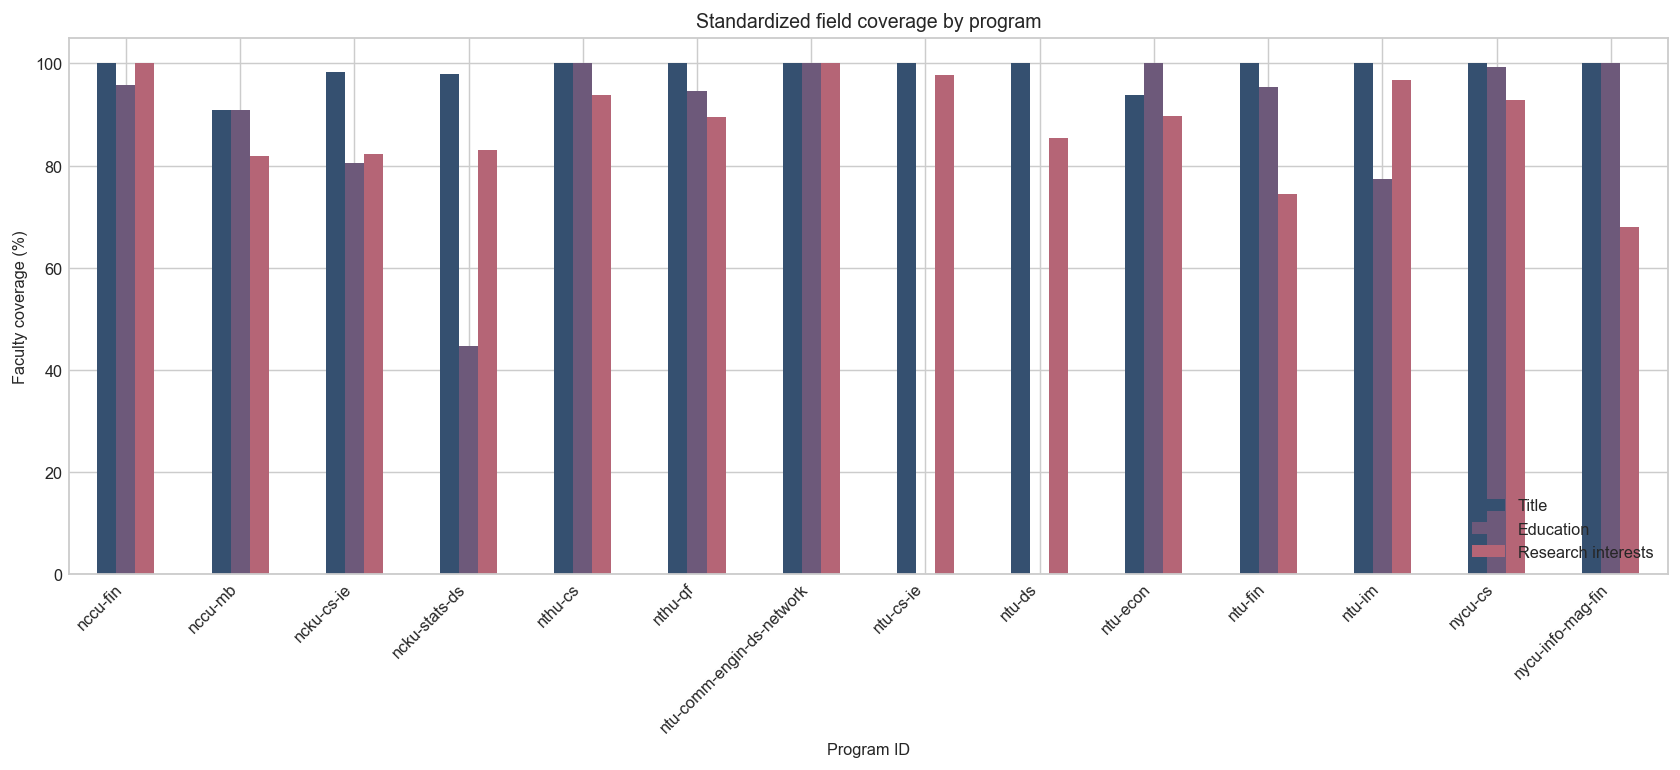

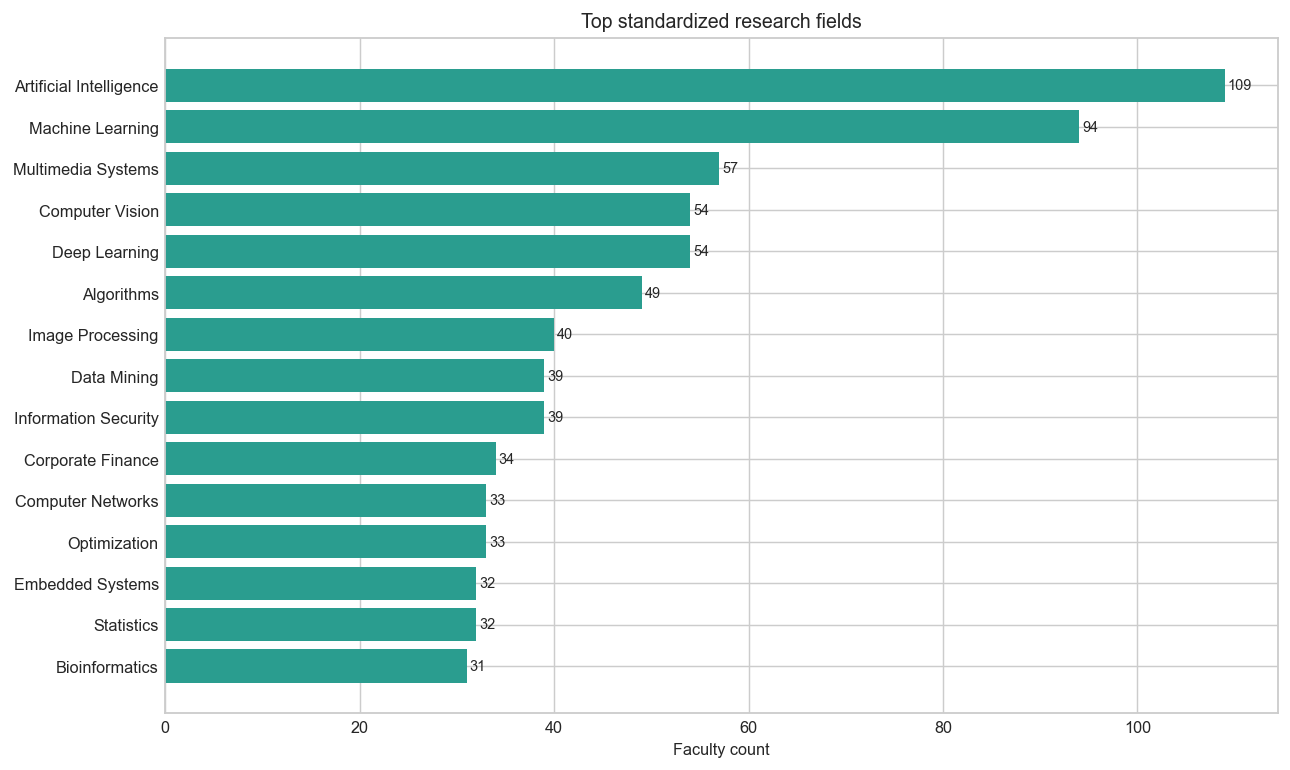

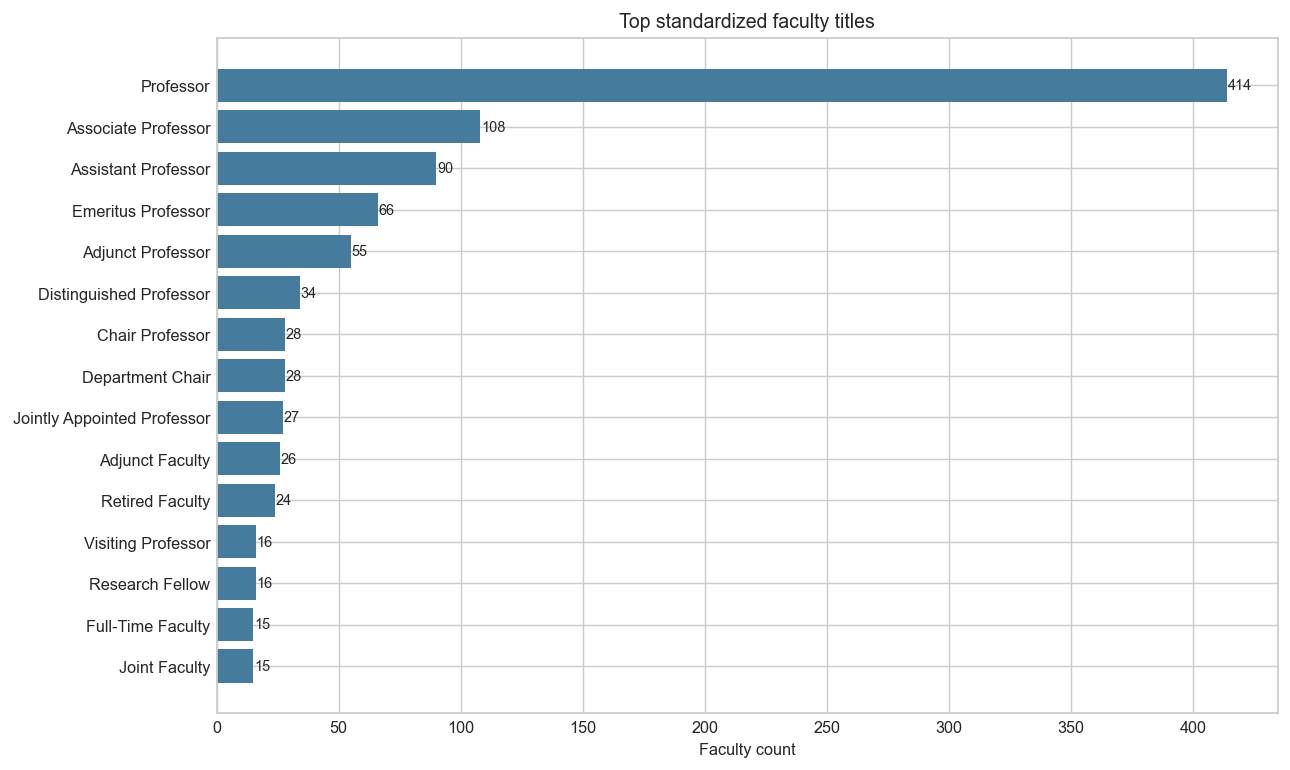

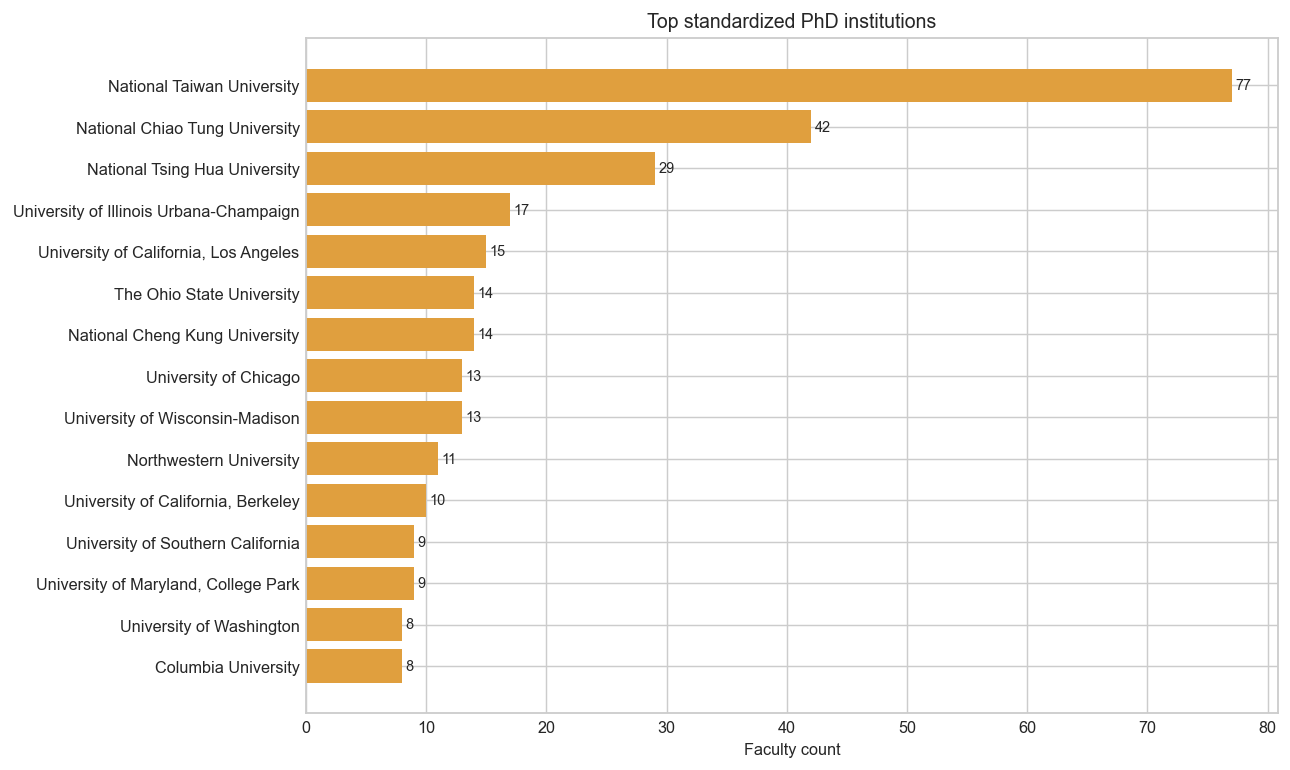

Generated 30 by-department charts under analysis\descriptive-stats-after-preprocessing\by_department


In [7]:
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 180, "font.size": 9})

plot_df = school_summary.set_index("school_id")[["title_coverage_pct", "education_coverage_pct", "research_interest_coverage_pct"]]
ax = plot_df.plot(kind="bar", figsize=(13, 6), color=["#355070", "#6d597a", "#b56576"])
ax.set_title("Standardized field coverage by program")
ax.set_xlabel("Program ID")
ax.set_ylabel("Faculty coverage (%)")
ax.set_ylim(0, 105)
ax.legend(["Title", "Education", "Research interests"], loc="lower right")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(ANALYSIS_DIR / "field_coverage_by_school.png", bbox_inches="tight")
plt.show()

def horizontal_bar(df, label_col, value_col, title, filename, color):
    view = df.head(15).sort_values(value_col)
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(view[label_col], view[value_col], color=color)
    ax.set_title(title)
    ax.set_xlabel("Faculty count")
    for y, value in enumerate(view[value_col]):
        ax.text(value + 0.3, y, str(value), va="center", fontsize=8)
    plt.tight_layout()
    plt.savefig(ANALYSIS_DIR / filename, bbox_inches="tight")
    plt.show()

horizontal_bar(top_research, "research_interest_en", "faculty_count", "Top standardized research fields", "top_research_fields.png", "#2a9d8f")
horizontal_bar(top_titles, "title_en", "faculty_count", "Top standardized faculty titles", "top_titles.png", "#457b9d")
horizontal_bar(top_phd, "institution_en", "faculty_count", "Top standardized PhD institutions", "top_phd_institutions.png", "#e09f3e")

# Per-department charts and grouped cross-department comparisons.
BY_DEPARTMENT_DIR = ANALYSIS_DIR / "by_department"
RESEARCH_BY_DEPARTMENT_DIR = BY_DEPARTMENT_DIR / "top_research_fields"
PHD_BY_DEPARTMENT_DIR = BY_DEPARTMENT_DIR / "top_phd_institutions"
RESEARCH_BY_DEPARTMENT_DIR.mkdir(parents=True, exist_ok=True)
PHD_BY_DEPARTMENT_DIR.mkdir(parents=True, exist_ok=True)

UNIVERSITY_ORDER = {"nccu": 0, "ncku": 1, "nthu": 2, "ntu": 3, "nycu": 4}


def department_sort_key(school_id):
    university = school_id.split("-", 1)[0]
    return (UNIVERSITY_ORDER.get(university, 99), university, school_id)


department_order = sorted(std_df["school_id"].unique(), key=department_sort_key)


def department_value_counts(long_df, school_id, value_col):
    view = long_df[long_df["school_id"] == school_id]
    if view.empty:
        return pd.Series(dtype="int64")
    return view.groupby(value_col)["faculty_id"].nunique().sort_values(ascending=False)


def save_department_bars(long_df, value_col, directory, subject, color, top_n=15):
    files = []
    for school_id in department_order:
        counts = department_value_counts(long_df, school_id, value_col).head(top_n).sort_values()
        height = max(4.2, 0.38 * max(len(counts), 6) + 1.8)
        fig, ax = plt.subplots(figsize=(10, height))
        if counts.empty:
            ax.axis("off")
            ax.text(0.5, 0.5, f"No standardized {subject.lower()} available", ha="center", va="center", fontsize=12)
        else:
            ax.barh(counts.index, counts.values, color=color)
            ax.set_xlabel("Faculty count")
            ax.set_xlim(0, max(counts.values) * 1.16)
            for y, value in enumerate(counts.values):
                ax.text(value + max(counts.values) * 0.015, y, str(value), va="center", fontsize=8)
        ax.set_title(f"{school_id}: Top {subject}")
        fig.tight_layout()
        path = directory / f"{school_id}.png"
        fig.savefig(path, bbox_inches="tight")
        plt.close(fig)
        files.append(path)
    return files


def save_department_comparison(long_df, value_col, directory, subject, filename, cmap, top_per_department=5):
    counts_by_department = {
        school_id: department_value_counts(long_df, school_id, value_col)
        for school_id in department_order
    }
    selected = {value for counts in counts_by_department.values() for value in counts.head(top_per_department).index}
    category_totals = {value: sum(int(counts.get(value, 0)) for counts in counts_by_department.values()) for value in selected}
    categories = sorted(selected, key=lambda value: (-category_totals[value], value))
    matrix = np.array([[int(counts_by_department[school_id].get(value, 0)) for value in categories] for school_id in department_order])
    width = max(14, min(32, 0.55 * max(len(categories), 1) + 5))
    fig, ax = plt.subplots(figsize=(width, 9))
    image = ax.imshow(matrix, aspect="auto", cmap=cmap, vmin=0)
    ax.set_xticks(range(len(categories)), labels=categories, rotation=60, ha="right")
    ax.set_yticks(range(len(department_order)), labels=department_order)
    ax.set_xlabel(subject)
    ax.set_ylabel("Program ID (grouped by university)")
    ax.set_title(f"Top {subject} by program (union of each program's Top {top_per_department})")
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            if matrix[row, col]:
                ax.text(col, row, str(matrix[row, col]), ha="center", va="center", fontsize=6, color="black")
    for row in range(1, len(department_order)):
        if department_order[row].split("-", 1)[0] != department_order[row - 1].split("-", 1)[0]:
            ax.axhline(row - 0.5, color="white", linewidth=3)
    fig.colorbar(image, ax=ax, label="Faculty count", shrink=0.8)
    fig.tight_layout()
    path = directory / filename
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)
    return path


department_plot_files = []
department_plot_files.extend(save_department_bars(
    research_long, "research_interest_en", RESEARCH_BY_DEPARTMENT_DIR, "Research Fields", "#2a9d8f"
))
department_plot_files.append(save_department_comparison(
    research_long, "research_interest_en", RESEARCH_BY_DEPARTMENT_DIR, "Research Fields",
    "all_departments_comparison.png", "YlGnBu"
))
department_plot_files.extend(save_department_bars(
    phd_df, "institution_en", PHD_BY_DEPARTMENT_DIR, "PhD Institutions", "#e09f3e"
))
department_plot_files.append(save_department_comparison(
    phd_df, "institution_en", PHD_BY_DEPARTMENT_DIR, "PhD Institutions",
    "all_departments_comparison.png", "YlOrBr"
))

print(f"Generated {len(department_plot_files)} by-department charts under {BY_DEPARTMENT_DIR.relative_to(PROJECT_ROOT)}")

## Generate reports and run validation checks

In [8]:
overall_coverage = {
    row["field"]: row["faculty_coverage_pct"] for row in field_summary.to_dict(orient="records")
}
review_counts = review_df.groupby(["field", "status"]).size().reset_index(name="source_entry_count")

analysis_report = f"""# 資料預處理後描述統計

產生時間：{RUN_TIMESTAMP}

## 分析範圍

- 教授資料：{len(std_df):,} 筆
- 研究所／系所：{std_df['school_id'].nunique()} 個
- Canonical 輸入：`data/data-collection/<school_id>/faculty.json`
- 執行環境：`{PYTHON_RUNTIME}`

## 欄位覆蓋率與詞彙收斂

{markdown_table(field_summary)}

## 各系所覆蓋率

{markdown_table(school_summary, max_rows=50)}

## 最常見研究領域

{markdown_table(top_research, max_rows=20)}

## 最常見職稱

{markdown_table(top_titles, max_rows=20)}

## 最常見博士畢業學校

{markdown_table(top_phd, max_rows=20)}

## 主要結果

- 標準化後最常見的研究領域是 `{top_research.iloc[0]['research_interest_en']}`（{int(top_research.iloc[0]['faculty_count'])} 人），其次是 `{top_research.iloc[1]['research_interest_en']}`（{int(top_research.iloc[1]['faculty_count'])} 人）。
- 最常見職稱是 `{top_titles.iloc[0]['title_en']}`（{int(top_titles.iloc[0]['faculty_count'])} 人）。
- 已成功辨識的博士學歷中，最常見學校是 `{top_phd.iloc[0]['institution_en']}`（{int(top_phd.iloc[0]['faculty_count'])} 人）。
- 學歷覆蓋率同時受官網缺值與來源格式影響；本流程只納入能辨識學位且可可靠對應學校的項目，不由任職或工作描述推測學歷。
- 研究資料將主要研究領域與研究領域摘要分開清洗及標準化，最後才合併 canonical 值；摘要中的防詐聲明等非研究內容不納入統計。
- `ntu-cs-ie` 與 `ntu-ds` 的系所官網來源未提供學歷，因此依收集政策維持空白，不使用外部個人網站補值。

## 解讀限制

- 覆蓋率表示該教授至少有一個可靠的標準化值；缺少來源資料不視為 0。
- 同一位教授可有多個職稱、學歷或研究領域，因此類別人次不會加總成教授總數。
- 無法解析或只能部分解析的來源值保留在 `data/data-preprocessing/manual_review_queue.csv`，不會硬猜後納入 canonical 統計。
- 系所間差異同時反映真實師資組成與來源網頁完整度，不宜直接解讀為系所排名。
"""
(ANALYSIS_DIR / "descriptive-stats-report.md").write_text(analysis_report, encoding="utf-8")

preprocessing_report = f"""# 資料預處理報告

產生時間：{RUN_TIMESTAMP}

## 目標與範圍

本流程處理 {std_df['school_id'].nunique()} 個研究所／系所、共 {len(std_df):,} 位教授的學歷、研究領域／興趣與職稱。教授姓名優先使用中文，只有缺少中文姓名時才使用英文；其餘三個欄位的 canonical 名稱一律使用英文。

## 執行內容

1. 依 `docs/data-collection-report.md` 載入各系所 canonical `faculty.json`，並確認 `faculty_id` 在全資料中唯一。
2. 完整保留中文與英文原始欄位；研究資料另保留主要研究領域與研究領域摘要的來源欄位，再新增各自的 canonical 結果、聯集候選與結構化學歷。
3. 移除網頁導覽文字、段落標題、空值標記，以及從相鄰網頁區塊誤抓進來的文字。
4. 使用可重現的雙語詞典把可辨識的中文值翻成英文候選；研究領域只以乾淨且等長的中英主要欄位作保守的逐項對齊提示。
5. 主要研究領域與研究領域摘要分別清洗及標準化後再取聯集並去重；主要欄位空白時摘要自然成為資料來源，兩者都有內容時也保留摘要提供的新主題。
6. 合併本質相同的名稱。例如 `AI`、`人工智慧` 統一為 `Artificial Intelligence`；`資產訂價`、`Asset Pricing` 統一為 `Asset Pricing`；`國立台灣大學`、`National Taiwan Univ.` 統一為 `National Taiwan University`；`專任副教授`、`Associate Professor` 統一為 `Associate Professor`。
7. 將學歷解析為學位、科系與學校三個部分，並統一輸出成 `Degree, Field, Institution`。
8. 無法可靠解析或只能部分解析的來源值寫入人工覆核佇列，不自行臆測翻譯。
9. 產生各系所覆蓋率、熱門研究領域、職稱與博士畢業學校等描述統計與圖表。

## 結果

{markdown_table(field_summary)}

教授層級的標準化覆蓋率為：職稱 {overall_coverage['title']:.1f}%、學歷 {overall_coverage['education']:.1f}%、研究領域／興趣 {overall_coverage['research_interest']:.1f}%。人工覆核佇列共有 {len(review_df):,} 個來源項目，主要是尚未能確定對應的學校／科系、過長自由文字或細分研究主題。`ntu-cs-ie` 與 `ntu-ds` 的學歷依官方來源維持空白。

最常見研究領域為 `{top_research.iloc[0]['research_interest_en']}`（{int(top_research.iloc[0]['faculty_count'])} 人）與 `{top_research.iloc[1]['research_interest_en']}`（{int(top_research.iloc[1]['faculty_count'])} 人）；最常見職稱是 `{top_titles.iloc[0]['title_en']}`（{int(top_titles.iloc[0]['faculty_count'])} 人）；成功辨識的博士學歷中，`{top_phd.iloc[0]['institution_en']}` 最常見（{int(top_phd.iloc[0]['faculty_count'])} 人）。

## 輸出檔案

### 標準化資料

- `data/data-preprocessing/faculty_standardized.json`：完整資料；陣列格式分開保留主要研究領域與研究領域摘要原文、各自 canonical 值、聯集候選、其他翻譯候選與結構化學歷。
- `data/data-preprocessing/faculty_standardized.csv`：UTF-8 with BOM 的平面版本；多值欄位以 ` | ` 分隔。
- `data/data-preprocessing/education_standardized_long.csv`：每列一筆標準化學歷。
- `data/data-preprocessing/research_interests_standardized_long.csv`：每列一個標準化研究領域。
- `data/data-preprocessing/titles_standardized_long.csv`：每列一個標準化職稱。
- `data/data-preprocessing/standardization_mapping.csv`：來源值到 canonical 值的稽核軌跡。
- `data/data-preprocessing/manual_review_queue.csv`：無法解析或只能部分解析的來源項目。

### 描述統計

- `analysis/descriptive-stats-after-preprocessing/descriptive-stats-report.md`
- `analysis/descriptive-stats-after-preprocessing/descriptive_stats.json`
- 各欄位／系所的 CSV 摘要與熱門類別表。
- 欄位覆蓋率、研究領域、職稱與博士畢業學校的 PNG 圖表。

## 重現方式

使用指定的 Python 3.12 環境執行 notebook：

```powershell
& 'python' -m jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=600 scripts/data-preprocessing/1_faculty_data_preprocessing.ipynb
```

## 限制與覆核建議

- 標準化器採保守策略。canonical 值缺失可能代表來源本來沒有資料、資料被網頁污染，或內容太模糊而無法可靠對應。
- 學歷解析以含學位的項目和已知學校別名為主；證書、博士後經歷與敘事型簡歷不視為學位。
- 研究領域會合併明確同義詞，但不強迫把每個細分主題歸到過寬類別。摘要中的防詐聲明等非研究文字會在標準化時排除，原文仍保留供稽核；若要提高召回率，請優先檢視 `manual_review_queue.csv`。
- 各來源網站的結構與完整度差異很大，覆蓋率不可直接解讀為系所或教授排名。
"""
(DOCS_DIR / "data-preprocessing-report.md").write_text(preprocessing_report, encoding="utf-8")

# Validation: outputs exist, IDs reconcile, canonical fields contain no Han characters,
# and long-table rows reconcile to list lengths in the JSON output.
expected_files = [
    JSON_OUTPUT, CSV_OUTPUT, MAPPING_OUTPUT, REVIEW_OUTPUT, EDUCATION_LONG_OUTPUT,
    RESEARCH_LONG_OUTPUT, TITLES_LONG_OUTPUT,
    ANALYSIS_DIR / "field_standardization_summary.csv",
    ANALYSIS_DIR / "coverage_by_school.csv",
    ANALYSIS_DIR / "top_research_fields.csv",
    ANALYSIS_DIR / "top_titles.csv",
    ANALYSIS_DIR / "top_phd_institutions.csv",
    ANALYSIS_DIR / "descriptive_stats.json",
    ANALYSIS_DIR / "descriptive-stats-report.md",
    ANALYSIS_DIR / "field_coverage_by_school.png",
    ANALYSIS_DIR / "top_research_fields.png",
    ANALYSIS_DIR / "top_titles.png",
    ANALYSIS_DIR / "top_phd_institutions.png",
    DOCS_DIR / "data-preprocessing-report.md",
    *department_plot_files,
]
assert all(path.exists() and path.stat().st_size > 0 for path in expected_files)
assert len(std_df) == len(raw_df) == len(csv_df)
assert set(std_df["faculty_id"]) == set(raw_df["faculty_id"])
assert len(education_long) == sum(map(len, std_df["education_standardized_en"]))
assert len(research_long) == sum(map(len, std_df["research_interests_standardized_en"]))
assert len(titles_long) == sum(map(len, std_df["titles_standardized_en"]))
for col in ["titles_standardized_en", "education_standardized_en", "research_interests_standardized_en"]:
    assert not any(has_han(value) for values in std_df[col] for value in values), f"Non-English canonical value in {col}"
assert std_df.apply(lambda row: row["professor_name"] == (clean_professor_name(row["name_zh"]) or clean_professor_name(row["name_en"])), axis=1).all()

print("Validation passed.")
print(f"Report: {DOCS_DIR / 'data-preprocessing-report.md'}")
print(f"Analysis: {ANALYSIS_DIR / 'descriptive-stats-report.md'}")
display(review_counts)

Validation passed.
Report: <project-root>\docs\data-preprocessing-report.md
Analysis: <project-root>\analysis\descriptive-stats-after-preprocessing\descriptive-stats-report.md


,field,status,source_entry_count
0,education,partial,405
1,research_interest,unresolved,1836
2,title,unresolved,99
